In [61]:
from pathlib import Path
import os
import re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multitest import multipletests

pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid", context="talk")

ancovas_mean_results_path = '../../../../results/pet/paper_analysis/ancova_rois_mean/'
ancovas_cerebellum_results_path = '../../../../results/pet/paper_analysis/ancova_rois_cerebellum/'
rois_to_lobe_csv = os.path.join('../../../../data/pet/', 'hammers_roi_to_lobe.csv')
rois_abbreviations_csv = os.path.join('../../../../data/pet/', 'roi_abbreviations.csv')
output_path = os.path.join(ancovas_mean_results_path, 'volcano_plots/')
os.makedirs(output_path, exist_ok=True)

# Load rois to lobe mapping
rois_to_lobe_df = pd.read_csv(rois_to_lobe_csv)
# Load abbreviations for ROIs
rois_abbreviations_df = pd.read_csv(rois_abbreviations_csv)


Top 10 significant ROIs:
MITG-L: Middle and inferior temporal gyrus (L)
SMG-L: Supramarginal gyrus (L)
LOrG-L: Lateral orbital gyrus (L)
PTL-L: Posterior temporal lobe (L)
IFG-L: Inferior frontal gyrus (L)
MFG-L: Middle frontal gyrus (L)
ACgG-R: Anterior cingulate gyrus (R)
SFG-R: Superior frontal gyrus (R)
PSgFC-R: Pre-subgenual frontal cortex (R)
POrG-L: Posterior orbital gyrus (L)


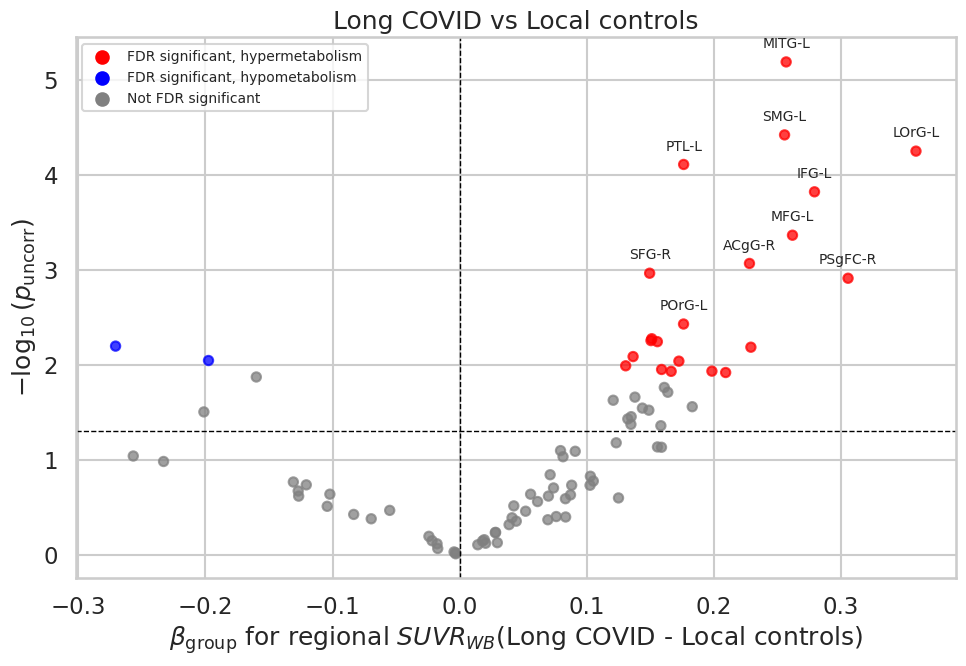

In [64]:
# Plot volcano plots for ANCOVA results for LC vs CEUNIM Controls
# Use the model with time_to_acquisition as a covariate
csv_filename = os.path.join(ancovas_mean_results_path, 'ancova_lc_vs_ceunim_controls_results_time_to_acquisition.csv')
# Load CSV
df = pd.read_csv(csv_filename)
df.head()
plot_df = df.copy()
# Use the ANCOVA group effect column for the x-axis.

# Clip zero p-values so -log10 remains finite.
plot_df["neg_log10_p_group"] = -np.log10(plot_df["p_group"].clip(lower=np.finfo(float).tiny))
# Use red color for hyper and blue for hypo, gray for non-significant:
plot_df["color"] = np.where(
    plot_df["p_fdr"] < 0.05,
    np.where(plot_df["delta_lc_minus_control"] > 0, "red",
             "blue"),
    "gray",
)
# Use a mapping of ROIs to lobes to group the ROIs by lobe
plot_df = plot_df.merge(rois_to_lobe_df, left_on="ROI", right_on="roi", how="left")
# rename category to lobe:
plot_df.rename(columns={"category": "lobe"}, inplace=True)
# Use a mapping of ROIs to abbreviations to add abbreviations for the ROIs
plot_df = plot_df.merge(rois_abbreviations_df, left_on="ROI", right_on="roi_full", how="left")

# Remove rows with "CSF/Ventricles" and "Not gray matter" in the lobe column
plot_df = plot_df[~plot_df["lobe"].isin(["CSF/Ventricles", "Not gray matter"])]
fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(
    plot_df["beta_group"], # use delta or betas for the x axis
    plot_df["neg_log10_p_group"],
    c=plot_df["color"],
    alpha=0.75,
    s=45,
)
ax.axvline(0, color="black", linewidth=1, linestyle="--")
ax.axhline(-np.log10(0.05), color="black", linewidth=1, linestyle="--")


ax.scatter([], [], color="red", label="FDR significant, hypermetabolism")
ax.scatter([], [], color="blue", label="FDR significant, hypometabolism")
ax.scatter([], [], color="gray", label="Not FDR significant")
ax.set(
    xlabel=r"$\beta_{\mathrm{group}}$ for regional $SUVR_{WB}$(Long COVID - Local controls)",
    ylabel=r"$-\log_{10}(p_{\mathrm{uncorr}})$",
    title="Long COVID vs Local controls",
)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(output_path, 'volcano_plot_lc_vs_ceunim_controls_time_to_acquisition.png'), dpi=300, bbox_inches="tight")
#plt.show()

# add names for the 10 highest significant ROIs to the plot
top_10_rois = plot_df.nlargest(10, "neg_log10_p_group")
for _, row in top_10_rois.iterrows():
    ax.annotate(
        row["abbreviation"],
        (row["beta_group"], row["neg_log10_p_group"]),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontsize=10,
    )
# Print the full name of the top 10 ROIs to the console
print("Top 10 significant ROIs:")
for _, row in top_10_rois.iterrows():
    print(f"{row['abbreviation']}: {row['full_name']}")
# save figure (before plt.show(), which clears the figure)
plt.savefig(os.path.join(output_path, 'volcano_plot_lc_vs_ceunim_controls_time_to_acquisition_with_roi_names.png'), dpi=300, bbox_inches="tight")
plt.show()


Top 10 significant ROIs:
MITG-L: Middle and inferior temporal gyrus (L)
SMG-L: Supramarginal gyrus (L)
LOrG-L: Lateral orbital gyrus (L)
PTL-L: Posterior temporal lobe (L)
IFG-L: Inferior frontal gyrus (L)
MFG-L: Middle frontal gyrus (L)
ACgG-R: Anterior cingulate gyrus (R)
SFG-R: Superior frontal gyrus (R)
PSgFC-R: Pre-subgenual frontal cortex (R)
POrG-L: Posterior orbital gyrus (L)
Hypometabolism ROIs:
Cereb-R: Cerebellum (R)
Pall-L: Pallidum (L)


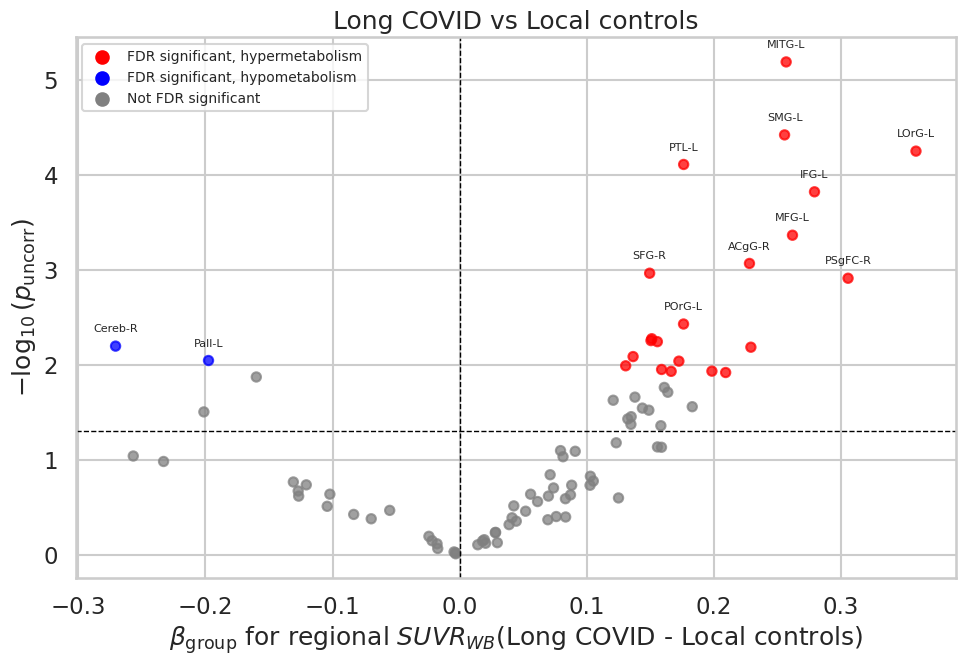

In [ ]:
# Plot volcano plots for ANCOVA results for LC vs CEUNIM Controls
# Use the model with time_to_acquisition as a covariate
csv_filename = os.path.join(ancovas_mean_results_path, 'ancova_lc_vs_ceunim_controls_results_time_to_acquisition.csv')
# Load CSV
df = pd.read_csv(csv_filename)
df.head()
plot_df = df.copy()
# Use the ANCOVA group effect column for the x-axis.

# Clip zero p-values so -log10 remains finite.
plot_df["neg_log10_p_group"] = -np.log10(plot_df["p_group"].clip(lower=np.finfo(float).tiny))
# Use red color for hyper and blue for hypo, gray for non-significant:
plot_df["color"] = np.where(
    plot_df["p_fdr"] < 0.05,
    np.where(plot_df["delta_lc_minus_control"] > 0, "red",
             "blue"),
    "gray",
)
# Use a mapping of ROIs to lobes to group the ROIs by lobe
plot_df = plot_df.merge(rois_to_lobe_df, left_on="ROI", right_on="roi", how="left")
# rename category to lobe:
plot_df.rename(columns={"category": "lobe"}, inplace=True)
# Use a mapping of ROIs to abbreviations to add abbreviations for the ROIs
plot_df = plot_df.merge(rois_abbreviations_df, left_on="ROI", right_on="roi_full", how="left")

# Remove rows with "CSF/Ventricles" and "Not gray matter" in the lobe column
plot_df = plot_df[~plot_df["lobe"].isin(["CSF/Ventricles", "Not gray matter"])]
fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(
    plot_df["beta_group"], # use delta or betas for the x axis
    plot_df["neg_log10_p_group"],
    c=plot_df["color"],
    alpha=0.75,
    s=45,
)
ax.axvline(0, color="black", linewidth=1, linestyle="--")
ax.axhline(-np.log10(0.05), color="black", linewidth=1, linestyle="--")

# add names for the 10 highest significant ROIs to the plot
top_10_rois = plot_df.nlargest(10, "neg_log10_p_group")
for _, row in top_10_rois.iterrows():
    ax.annotate(
        row["abbreviation"],
        (row["beta_group"], row["neg_log10_p_group"]),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontsize=10,
    )
# print the full name of the top 10 ROIs to the console
print("Top 10 significant ROIs:")
for _, row in top_10_rois.iterrows():
    print(f"{row['abbreviation']}: {row['full_name']}")
# Add names to hypometabolism ROIs
hypo_rois = plot_df[(plot_df["p_fdr"] < 0.05) & (plot_df["delta_lc_minus_control"] < 0)]
for _, row in hypo_rois.iterrows():
    ax.annotate(
        row["abbreviation"],
        (row["beta_group"], row["neg_log10_p_group"]),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontsize=10,
    )
# Print the full name of the hypometabolism ROIs to the console
print("Hypometabolism ROIs:")
for _, row in hypo_rois.iterrows():
    print(f"{row['abbreviation']}: {row['full_name']}")

ax.scatter([], [], color="red", label="FDR significant, hypermetabolism")
ax.scatter([], [], color="blue", label="FDR significant, hypometabolism")
ax.scatter([], [], color="gray", label="Not FDR significant")
ax.set(
    xlabel=r"$\beta_{\mathrm{group}}$ for regional $SUVR_{WB}$(Long COVID - Local controls)",
    ylabel=r"$-\log_{10}(p_{\mathrm{uncorr}})$",
    title="Long COVID vs Local controls",
)
ax.legend(fontsize=10)
plt.tight_layout()

# save figure (before plt.show(), which clears the figure)
plt.savefig(os.path.join(output_path, 'volcano_plot_lc_vs_ceunim_controls_time_to_acquisition_with_roi_names.png'), dpi=300, bbox_inches="tight")
plt.show()


Top 10 significant ROIs:
SMG-L: Supramarginal gyrus (L)
LOrG-L: Lateral orbital gyrus (L)
MFG-L: Middle frontal gyrus (L)
PTL-L: Posterior temporal lobe (L)
MITG-L: Middle and inferior temporal gyrus (L)
IFG-L: Inferior frontal gyrus (L)
BStem: Brainstem (excl. substantia nigra)
ACgG-R: Anterior cingulate gyrus (R)
SFG-R: Superior frontal gyrus (R)
AnG-L: Angular gyrus (L)
Hypometabolism ROIs:
BStem: Brainstem (excl. substantia nigra)
Cereb-R: Cerebellum (R)
Pall-L: Pallidum (L)
Cereb-L: Cerebellum (L)


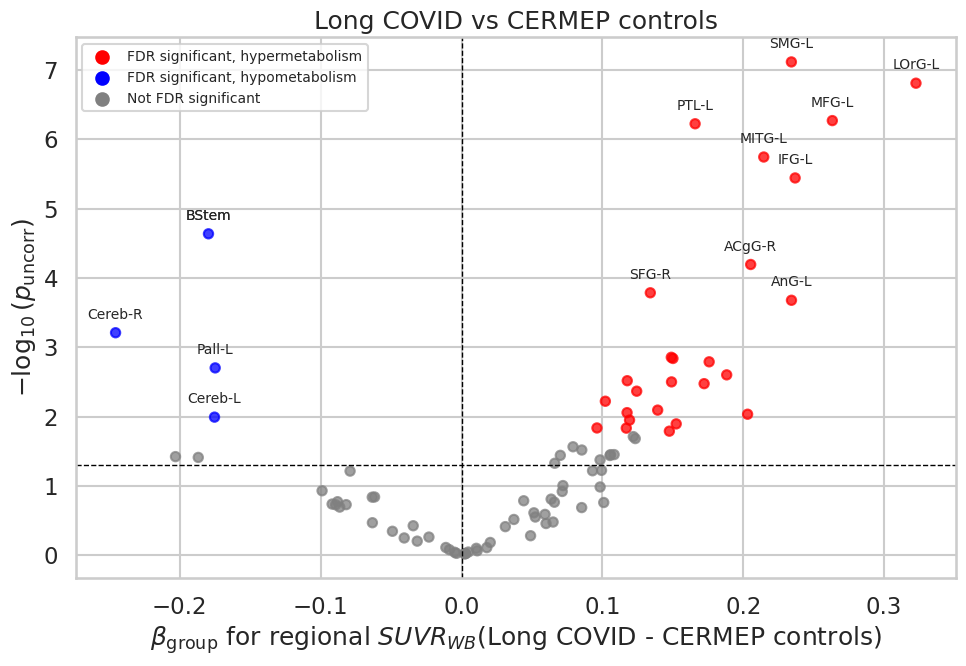

In [73]:
# Plot volcano plots for ANCOVA results for LC vs CERMEP Controls
# Use the model with time_to_acquisition as a covariate
csv_filename = os.path.join(ancovas_mean_results_path, 'ancova_lc_vs_cermep_controls_results.csv')
# Load CSV
df = pd.read_csv(csv_filename)
df.head()
plot_df = df.copy()
# Use the ANCOVA group effect column for the x-axis.

# Clip zero p-values so -log10 remains finite.
plot_df["neg_log10_p_group"] = -np.log10(plot_df["p_group"].clip(lower=np.finfo(float).tiny))
# Use red color for hyper and blue for hypo, gray for non-significant:
plot_df["color"] = np.where(
    plot_df["p_fdr"] < 0.05,
    np.where(plot_df["delta_lc_minus_control"] > 0, "red",
             "blue"),
    "gray",
)
# Use a mapping of ROIs to lobes to group the ROIs by lobe
plot_df = plot_df.merge(rois_to_lobe_df, left_on="ROI", right_on="roi", how="left")
# rename category to lobe:
plot_df.rename(columns={"category": "lobe"}, inplace=True)
# Use a mapping of ROIs to abbreviations to add abbreviations for the ROIs
plot_df = plot_df.merge(rois_abbreviations_df, left_on="ROI", right_on="roi_full", how="left")

# Remove rows with "CSF/Ventricles" and "Not gray matter" in the lobe column
plot_df = plot_df[~plot_df["lobe"].isin(["CSF/Ventricles", "Not gray matter"])]
fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(
    plot_df["beta_group"], # use delta or betas for the x axis
    plot_df["neg_log10_p_group"],
    c=plot_df["color"],
    alpha=0.75,
    s=45,
)
ax.axvline(0, color="black", linewidth=1, linestyle="--")
ax.axhline(-np.log10(0.05), color="black", linewidth=1, linestyle="--")

# add names for the 10 highest significant ROIs to the plot
top_10_rois = plot_df.nlargest(10, "neg_log10_p_group")
for _, row in top_10_rois.iterrows():
    ax.annotate(
        row["abbreviation"],
        (row["beta_group"], row["neg_log10_p_group"]),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontsize=10,
    )
# Print the full name of the top 10 ROIs to the console
print("Top 10 significant ROIs:")
for _, row in top_10_rois.iterrows():
    print(f"{row['abbreviation']}: {row['full_name']}")

# Aadd names to hypometabolism ROIs
hypo_rois = plot_df[(plot_df["p_fdr"] < 0.05) & (plot_df["delta_lc_minus_control"] < 0)]
for _, row in hypo_rois.iterrows():
    ax.annotate(
        row["abbreviation"],
        (row["beta_group"], row["neg_log10_p_group"]),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontsize=10,
    )
# Print the full name of the hypometabolism ROIs to the console
print("Hypometabolism ROIs:")
for _, row in hypo_rois.iterrows():
    print(f"{row['abbreviation']}: {row['full_name']}")
ax.scatter([], [], color="red", label="FDR significant, hypermetabolism")
ax.scatter([], [], color="blue", label="FDR significant, hypometabolism")
ax.scatter([], [], color="gray", label="Not FDR significant")
ax.set(
    xlabel=r"$\beta_{\mathrm{group}}$ for regional $SUVR_{WB}$(Long COVID - CERMEP controls)",
    ylabel=r"$-\log_{10}(p_{\mathrm{uncorr}})$",
    title="Long COVID vs CERMEP controls",
)
ax.legend(fontsize=10)
plt.tight_layout()

# save figure (before plt.show(), which clears the figure)
plt.savefig(os.path.join(output_path, 'volcano_plot_lc_vs_cermep_controls_with_roi_names.png'), dpi=300, bbox_inches="tight")
plt.show()


Top 10 significant ROIs:
SMG-L: Supramarginal gyrus (L)
ACgG-R: Anterior cingulate gyrus (R)
PTL-L: Posterior temporal lobe (L)
MITG-L: Middle and inferior temporal gyrus (L)
MFG-L: Middle frontal gyrus (L)
LOrG-L: Lateral orbital gyrus (L)
IFG-L: Inferior frontal gyrus (L)
AnG-L: Angular gyrus (L)
aSTG-L: Superior temporal gyrus, anterior part (L)
SFG-R: Superior frontal gyrus (R)
Hypometabolism ROIs:
Cereb-R: Cerebellum (R)
BStem: Brainstem (excl. substantia nigra)
Pall-L: Pallidum (L)


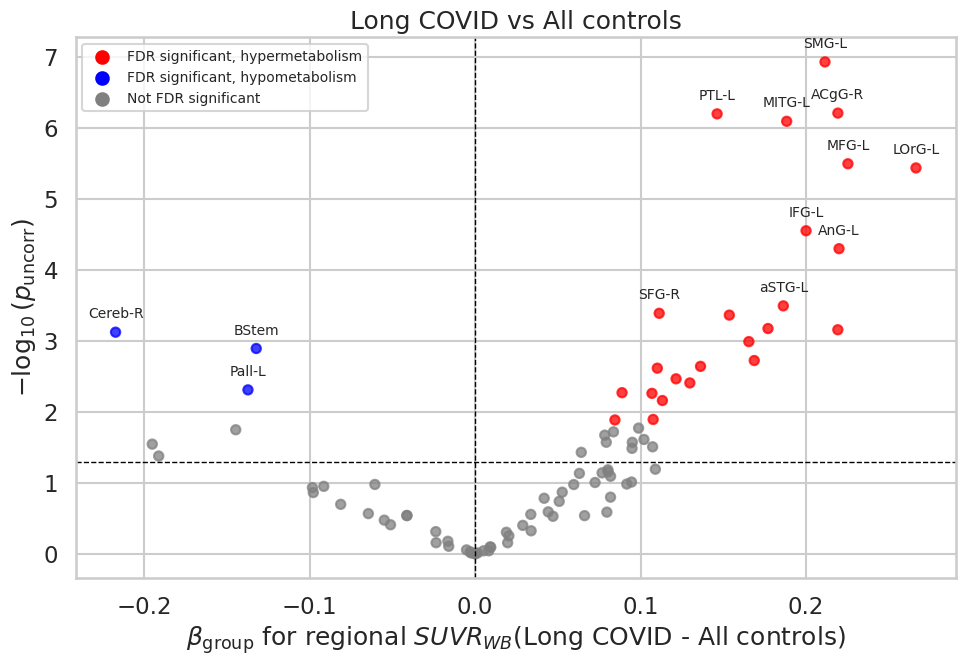

In [76]:
# Plot volcano plots for ANCOVA results for LC vs All Controls
# Use the model with time_to_acquisition as a covariate
csv_filename = os.path.join(ancovas_mean_results_path, 'ancova_lc_vs_all_controls_results.csv')
# Load CSV
df = pd.read_csv(csv_filename)
df.head()
plot_df = df.copy()
# Use the ANCOVA group effect column for the x-axis.

# Clip zero p-values so -log10 remains finite.
plot_df["neg_log10_p_group"] = -np.log10(plot_df["p_group"].clip(lower=np.finfo(float).tiny))
# Use red color for hyper and blue for hypo, gray for non-significant:
plot_df["color"] = np.where(
    plot_df["p_fdr"] < 0.05,
    np.where(plot_df["delta_lc_minus_control"] > 0, "red",
             "blue"),
    "gray",
)
# Use a mapping of ROIs to lobes to group the ROIs by lobe
plot_df = plot_df.merge(rois_to_lobe_df, left_on="ROI", right_on="roi", how="left")
# rename category to lobe:
plot_df.rename(columns={"category": "lobe"}, inplace=True)
# Use a mapping of ROIs to abbreviations to add abbreviations for the ROIs
plot_df = plot_df.merge(rois_abbreviations_df, left_on="ROI", right_on="roi_full", how="left")

# Remove rows with "CSF/Ventricles" and "Not gray matter" in the lobe column
plot_df = plot_df[~plot_df["lobe"].isin(["CSF/Ventricles", "Not gray matter"])]
fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(
    plot_df["beta_group"], # use delta or betas for the x axis
    plot_df["neg_log10_p_group"],
    c=plot_df["color"],
    alpha=0.75,
    s=45,
)
ax.axvline(0, color="black", linewidth=1, linestyle="--")
ax.axhline(-np.log10(0.05), color="black", linewidth=1, linestyle="--")

# add names for the 10 highest significant ROIs to the plot
top_10_rois = plot_df.nlargest(10, "neg_log10_p_group")
for _, row in top_10_rois.iterrows():
    ax.annotate(
        row["abbreviation"],
        (row["beta_group"], row["neg_log10_p_group"]),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontsize=10,
    )
# print the full name of the top 10 ROIs to the console
print("Top 10 significant ROIs:")
for _, row in top_10_rois.iterrows():
    print(f"{row['abbreviation']}: {row['full_name']}")
# Aadd names to hypometabolism ROIs
hypo_rois = plot_df[(plot_df["p_fdr"] < 0.05) & (plot_df["delta_lc_minus_control"] < 0)]
for _, row in hypo_rois.iterrows():
    ax.annotate(
        row["abbreviation"],
        (row["beta_group"], row["neg_log10_p_group"]),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontsize=10,
    )
# print the full name of the hypometabolism ROIs to the console
print("Hypometabolism ROIs:")
for _, row in hypo_rois.iterrows():
    print(f"{row['abbreviation']}: {row['full_name']}")
ax.scatter([], [], color="red", label="FDR significant, hypermetabolism")
ax.scatter([], [], color="blue", label="FDR significant, hypometabolism")
ax.scatter([], [], color="gray", label="Not FDR significant")
ax.set(
    xlabel=r"$\beta_{\mathrm{group}}$ for regional $SUVR_{WB}$(Long COVID - All controls)",
    ylabel=r"$-\log_{10}(p_{\mathrm{uncorr}})$",
    title="Long COVID vs All controls",
)
ax.legend(fontsize=10)
plt.tight_layout()

# save figure (before plt.show(), which clears the figure)
plt.savefig(os.path.join(output_path, 'volcano_plot_lc_vs_all_controls_with_roi_names.png'), dpi=300, bbox_inches="tight")
plt.show()
